# 03 — The 15-Year Story
**Stage:** Description

**TL;DR:** From 2011 to 2025 Karnataka's **peak demand grew 2.35× (7.8 → 18.4 GW)** and average demand 1.83×. The grid turned into a **daytime grid**: the daily peak moved from **~8 pm (58% of days in 2011–15) to ~10 am (96% of days in 2021–26)**, and daytime load grew **66%** vs only **21–24%** at night and in the evening. Coal's share fell from 49% to 17% as solar arrived, then climbed back to ~30% as demand outgrew new solar. Grid-stress hours dropped from **72% to ~2%**.

## 1. Question
How did Karnataka's electricity system change from 2011 to 2026?

Sub-questions:
1. How much did demand grow — on average and at the peak?
2. **When** in the day does Karnataka use power, and did that change?
3. Where does the power come from, and how did the mix change?
4. Did the grid become more reliable?

This notebook only **describes** (Riley: separate description from evaluation). It gives the context —
the *Situation* — for the final report. No causes are claimed here.

## 2. Expectation *(written before running)*
From the quick exploration during project research, I expect:
- Peak demand roughly **doubled or more** (≈8 GW in 2011 → ≈18 GW in 2026).
- The **daily peak moved from evening (~8 pm) to late morning (~10 am)**.
- Growth concentrated in **daytime hours**; night-time load grew much less.
- **Solar** grew from almost nothing to one of the largest sources; **coal** fell, then partly recovered.
- Grid frequency problems (a sign of shortage) were common in 2011–2012 and became rare.

Caution: annual averages for **2023** (Jan–Jul missing) and **2026** (ends 19 Aug) are not comparable with
full years — I will mark or exclude them.

## 3. Data used
`data/processed/load_hourly.parquet`, `generation_daily.parquet` (from Notebook 02). Years with less than 90%
of hours present are marked as partial.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from src import config, plots

plots.setup()
pd.set_option("display.width", 200)

load = pd.read_parquet(config.DATA_PROCESSED / "load_hourly.parquet")
gen = pd.read_parquet(config.DATA_PROCESSED / "generation_daily.parquet")
load["year"], load["month"], load["hour"] = load.index.year, load.index.month, load.index.hour

# coverage = hours present / hours in the full calendar year (so a year that ends in August is partial)
hours_in_year = pd.Series({y: (366 if pd.Timestamp(f"{y}-12-31").dayofyear == 366 else 365) * 24 for y in load.year.unique()})
coverage = load.groupby("year").load_mw.count() / hours_in_year
full_years = coverage[coverage >= 0.9].index.tolist()
print("Coverage by year:", (coverage * 100).round(0).to_dict())
print("Full years used for annual comparisons:", full_years)

Coverage by year: {2011: 99.0, 2012: 99.0, 2013: 94.0, 2014: 95.0, 2015: 97.0, 2016: 97.0, 2017: 99.0, 2018: 98.0, 2019: 99.0, 2020: 100.0, 2021: 100.0, 2022: 100.0, 2023: 48.0, 2024: 100.0, 2025: 100.0, 2026: 61.0}
Full years used for annual comparisons: [2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2024, 2025]


## 4. Analysis
### Step 4.1 — How much did demand grow?
*Why:* the most basic fact about the system. Average load = total energy; peak load = what the grid must be
built to handle.

In [2]:
annual = load.groupby("year").load_mw.agg(avg_mw="mean", peak_mw="max")
annual["load_factor"] = annual.avg_mw / annual.peak_mw
annual["partial"] = ~annual.index.isin(full_years)
annual.round(2)

,avg_mw,peak_mw,load_factor,partial
year,,,,
2011,5972.71,7815.00,0.76,False
2012,6489.47,8549.00,0.76,False
2013,6513.11,8761.00,0.74,False
2014,6911.87,9503.00,0.73,False
2015,6978.07,9549.00,0.73,False
2016,7610.69,9870.57,0.77,False
2017,7640.82,10242.00,0.75,False
2018,8211.13,11232.68,0.73,False
2019,8280.43,12880.53,0.64,False


avg_mw: 5,973 MW (2011) -> 10,926 MW (2025)  = x1.83, CAGR 4.4%/yr
peak_mw: 7,815 MW (2011) -> 18,395 MW (2025)  = x2.35, CAGR 6.3%/yr


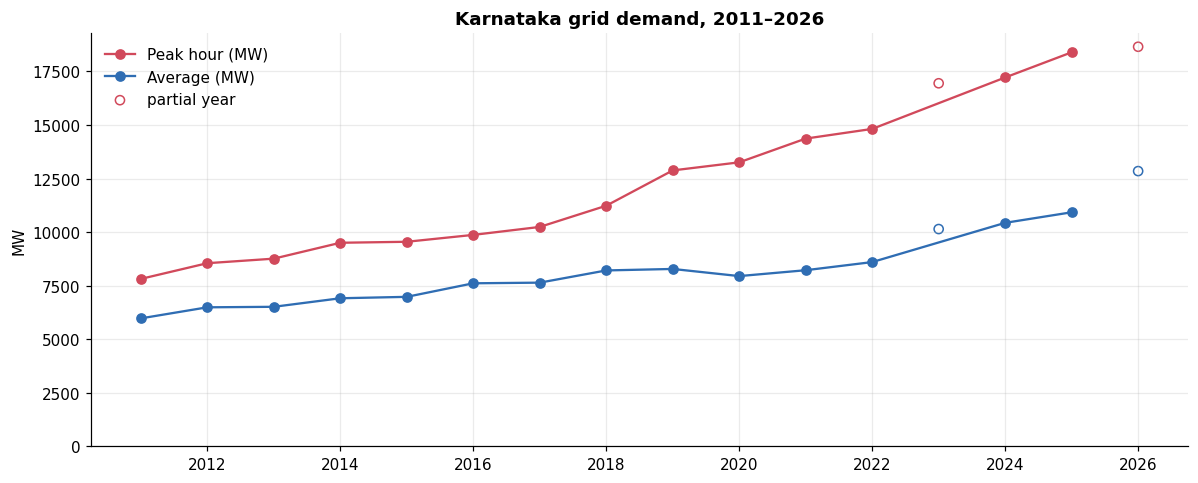

In [3]:
f = annual.loc[full_years]
y0, y1 = full_years[0], full_years[-1]
n = y1 - y0
for col in ["avg_mw", "peak_mw"]:
    growth = f.loc[y1, col] / f.loc[y0, col]
    print(f"{col}: {f.loc[y0, col]:,.0f} MW ({y0}) -> {f.loc[y1, col]:,.0f} MW ({y1})  "
          f"= x{growth:.2f}, CAGR {(growth ** (1 / n) - 1) * 100:.1f}%/yr")

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(f.index, f.peak_mw, marker="o", color=plots.COLORS["highlight"], label="Peak hour (MW)")
ax.plot(f.index, f.avg_mw, marker="o", color=plots.COLORS["load"], label="Average (MW)")
part = annual[annual.partial]
ax.scatter(part.index, part.peak_mw, facecolors="none", edgecolors=plots.COLORS["highlight"], label="partial year")
ax.scatter(part.index, part.avg_mw, facecolors="none", edgecolors=plots.COLORS["load"])
ax.set_title("Karnataka grid demand, 2011–2026")
ax.set_ylabel("MW"); ax.legend(); ax.set_ylim(0)
plt.tight_layout(); plots.save(fig, "03_demand_growth"); plt.show()

_What I see:_ see Result.

### Step 4.2 — When in the year?
*Why:* demand in Karnataka is seasonal; the monsoon months behave very differently from summer.

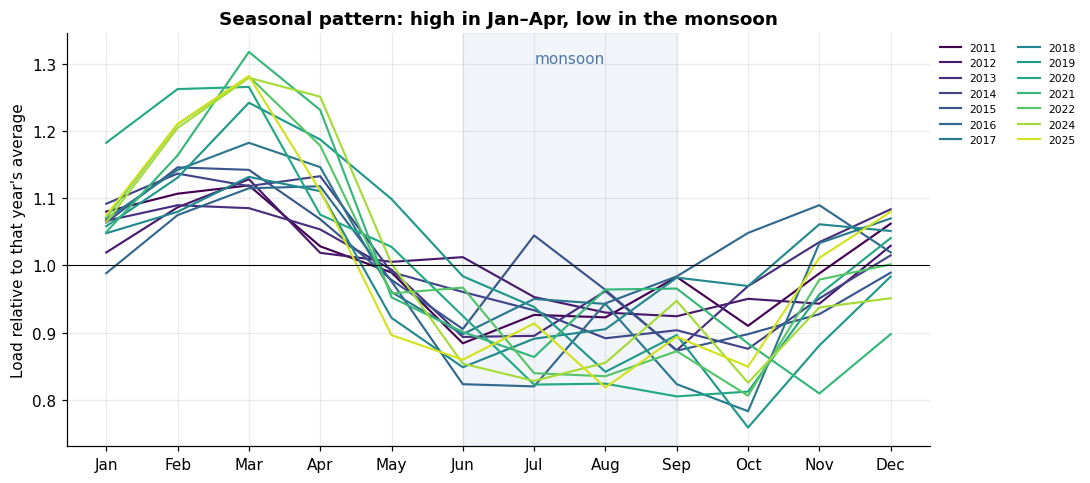

,avg relative load
month,
1,1.07
2,1.15
3,1.19
4,1.12
5,0.98
6,0.91
7,0.90
8,0.90
9,0.91


In [4]:
monthly = load[load.year.isin(full_years)].pivot_table(index="month", columns="year", values="load_mw")
norm = monthly / monthly.mean()          # each year relative to its own average
fig, ax = plt.subplots(figsize=(10, 4.5))
for yr in norm.columns:
    ax.plot(norm.index, norm[yr], color=plt.cm.viridis((yr - 2011) / 15), lw=1.4, label=yr)
ax.axhline(1, color="black", lw=0.7)
ax.axvspan(6, 9, color="#4e79a7", alpha=0.08)
ax.text(7.5, ax.get_ylim()[1] * 0.98, "monsoon", ha="center", va="top", color="#4e79a7")
ax.set_xticks(range(1, 13), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_ylabel("Load relative to that year's average")
ax.set_title("Seasonal pattern: high in Jan–Apr, low in the monsoon")
ax.legend(ncol=2, fontsize=7, loc="upper right", bbox_to_anchor=(1.18, 1))
plt.tight_layout(); plots.save(fig, "03_seasonal_pattern"); plt.show()
(norm.mean(axis=1)).round(2).to_frame("avg relative load")

### Step 4.3 — When in the day? Did the daily shape change?
*Why:* this is the key context for our main question — which hours carry the load tells us who is using it.

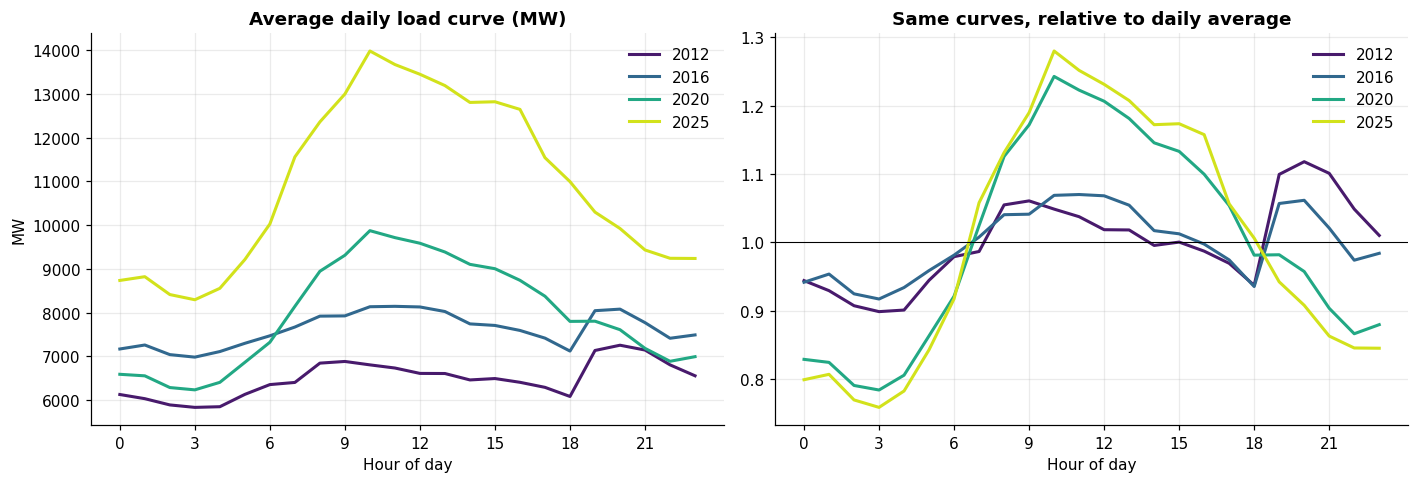

In [5]:
pick = [y for y in [2012, 2016, 2020, 2025] if y in full_years]
prof = load[load.year.isin(pick)].pivot_table(index="hour", columns="year", values="load_mw")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for yr in pick:
    c = plt.cm.viridis((yr - 2011) / 15)
    axes[0].plot(prof.index, prof[yr], color=c, lw=2, label=yr)
    axes[1].plot(prof.index, prof[yr] / prof[yr].mean(), color=c, lw=2, label=yr)
axes[0].set_title("Average daily load curve (MW)"); axes[0].set_ylabel("MW")
axes[1].set_title("Same curves, relative to daily average"); axes[1].axhline(1, color="black", lw=0.7)
for ax in axes:
    ax.set_xlabel("Hour of day"); ax.set_xticks(range(0, 24, 3)); ax.legend()
plt.tight_layout(); plots.save(fig, "03_daily_shape"); plt.show()

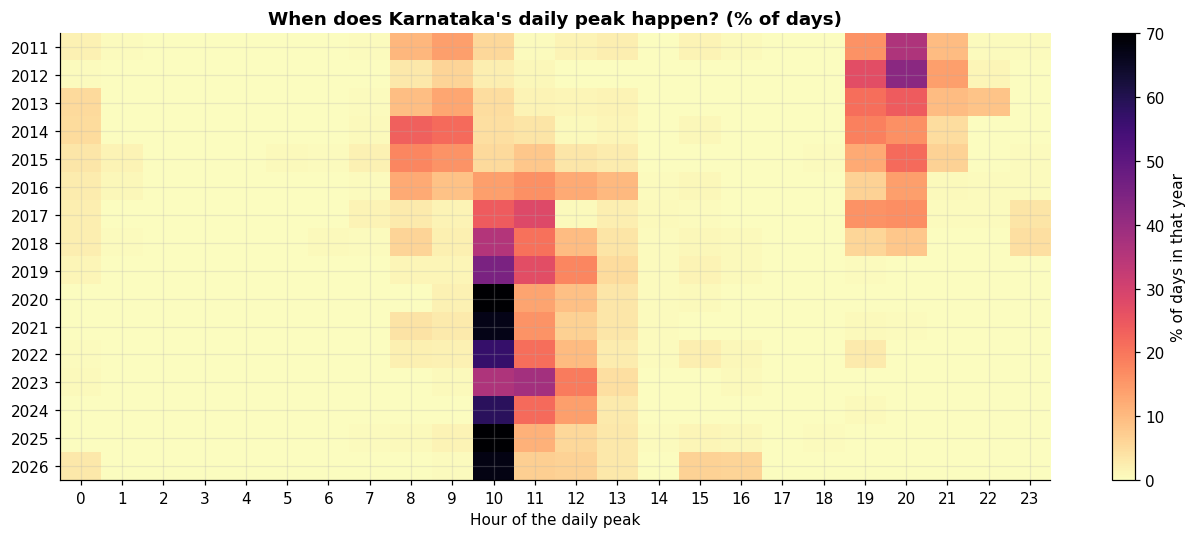

slot,evening 17–22h,morning/midday 6–13h,other
period,,,
2011–15,58.0,38.0,4.0
2016–20,14.0,81.0,5.0
2021–26,1.0,96.0,3.0


In [6]:
# Which hour is the daily peak? Share of days per peak hour, by year
daily_peak_hour = load.dropna(subset=["load_mw"]).groupby(load.dropna(subset=["load_mw"]).index.normalize()).load_mw.idxmax()
ph = pd.DataFrame({"year": daily_peak_hour.index.year, "hour": daily_peak_hour.dt.hour})
share = pd.crosstab(ph.year, ph.hour, normalize="index") * 100

fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(share.reindex(columns=range(24), fill_value=0), cmap="magma_r", aspect="auto", vmin=0, vmax=70)
ax.set_xticks(range(24)); ax.set_yticks(range(len(share)), share.index)
ax.set_xlabel("Hour of the daily peak"); ax.set_title("When does Karnataka's daily peak happen? (% of days)")
fig.colorbar(im, ax=ax, label="% of days in that year")
plt.tight_layout(); plots.save(fig, "03_peak_hour_shift"); plt.show()

ph["period"] = np.select([ph.year <= 2015, ph.year <= 2020], ["2011–15", "2016–20"], "2021–26")
ph["slot"] = np.select([ph.hour.between(6, 13), ph.hour.between(17, 22)], ["morning/midday 6–13h", "evening 17–22h"], "other")
(pd.crosstab(ph.period, ph.slot, normalize="index") * 100).round(0)

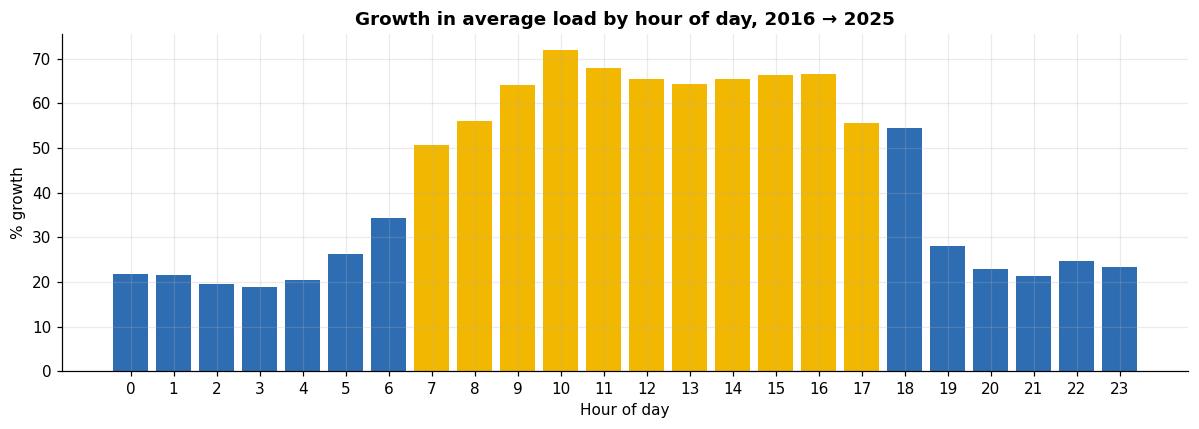

daytime (9–16h) growth: 66%   night (0–5h): 21%   evening (19–22h): 24%


In [7]:
# Which hours grew the most? First vs last full year with a stable data set
a, b = 2016, max(y for y in full_years if y <= 2025)
p = load[load.year.isin([a, b])].pivot_table(index="hour", columns="year", values="load_mw")
growth = (p[b] / p[a] - 1) * 100
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(growth.index, growth.values, color=[plots.COLORS["solar"] if 7 <= h <= 17 else plots.COLORS["load"] for h in growth.index])
ax.set_title(f"Growth in average load by hour of day, {a} → {b}")
ax.set_xlabel("Hour of day"); ax.set_ylabel("% growth"); ax.set_xticks(range(24))
plt.tight_layout(); plots.save(fig, "03_growth_by_hour"); plt.show()
print(f"daytime (9–16h) growth: {growth.loc[9:16].mean():.0f}%   night (0–5h): {growth.loc[0:5].mean():.0f}%   evening (19–22h): {growth.loc[19:22].mean():.0f}%")

### Step 4.4 — Where does the power come from?
*Why:* the supply side explains how the system coped with the demand growth. Units: million units (MU) per
day, from KPTCL's station reports.

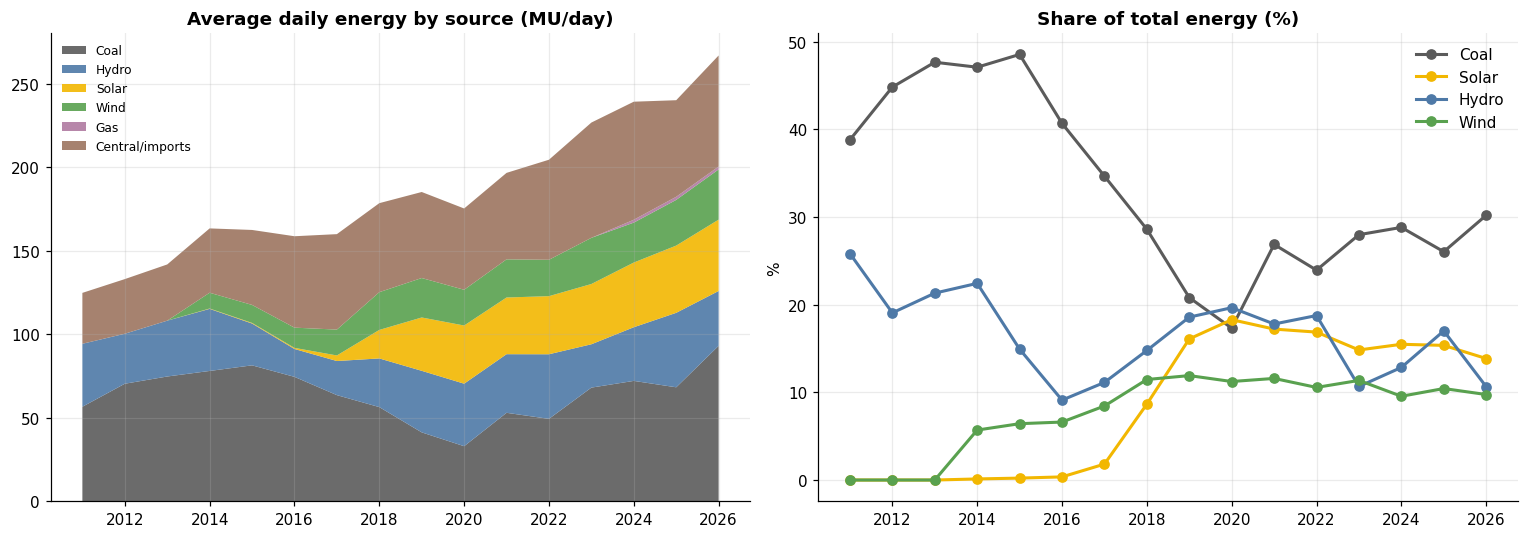

,coal,hydro,solar,wind,gas,central_import
date,,,,,,
2011,39.0,26.0,0.0,0.0,0.0,21.0
2012,45.0,19.0,0.0,0.0,0.0,21.0
2013,48.0,21.0,0.0,0.0,0.0,21.0
2014,47.0,22.0,0.0,6.0,0.0,23.0
2015,49.0,15.0,0.0,6.0,0.0,27.0
2016,41.0,9.0,0.0,7.0,0.0,30.0
2017,35.0,11.0,2.0,8.0,0.0,31.0
2018,29.0,15.0,9.0,11.0,0.0,27.0
2019,21.0,19.0,16.0,12.0,0.0,26.0


In [8]:
gy = gen.groupby(gen.index.year).mean()
gy = gy[gy.index <= 2026]
mix = gy[plots.SOURCE_ORDER].fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].stackplot(mix.index, [mix[s] for s in plots.SOURCE_ORDER],
                  labels=[plots.SOURCE_LABELS[s] for s in plots.SOURCE_ORDER],
                  colors=[plots.COLORS[s] for s in plots.SOURCE_ORDER], alpha=0.9)
axes[0].set_title("Average daily energy by source (MU/day)"); axes[0].legend(loc="upper left", fontsize=8)
share_mix = mix.div(gy["total"], axis=0) * 100
for s in ["coal", "solar", "hydro", "wind"]:
    axes[1].plot(share_mix.index, share_mix[s], marker="o", color=plots.COLORS[s], label=plots.SOURCE_LABELS[s], lw=2)
axes[1].set_title("Share of total energy (%)"); axes[1].set_ylabel("%"); axes[1].legend()
plt.tight_layout(); plots.save(fig, "03_generation_mix"); plt.show()
share_mix.round(0)

### Step 4.5 — Did the grid become more reliable?
*Why:* when demand exceeds supply, grid frequency drops below 50 Hz. The share of hours below 49.9 Hz is a
simple stress indicator. (Frequency is shared across the whole southern/national grid, so it reflects more
than Karnataka alone.)

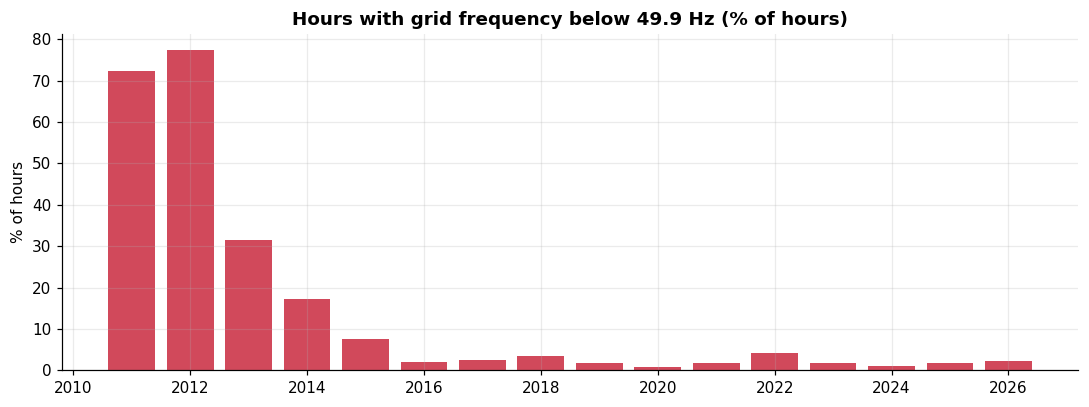

year,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
% hours < 49.9 Hz,72.3,77.4,31.5,17.2,7.6,2.0,2.4,3.5,1.8,0.8,1.7,4.2,1.7,1.0,1.7,2.2


In [9]:
stress = load.dropna(subset=["freq_hz"]).groupby("year").freq_hz.apply(lambda s: (s < 49.9).mean() * 100)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(stress.index, stress.values, color=plots.COLORS["highlight"])
ax.set_title("Hours with grid frequency below 49.9 Hz (% of hours)")
ax.set_ylabel("% of hours")
plt.tight_layout(); plots.save(fig, "03_grid_stress"); plt.show()
stress.round(1).to_frame("% hours < 49.9 Hz").T

## 5. Result
**1. Growth (full years only, 2011 → 2025)**
- Average load: 5,973 → 10,926 MW (**×1.83**, 4.4%/yr)
- Peak load: 7,815 → 18,395 MW (**×2.35**, 6.3%/yr)
- Peak grew faster than average, so the **load factor fell from 0.76 to ~0.59** — the grid became "peakier" (more expensive to serve).
- Visible step-ups in **2019** and **2023–24**.

**2. Season:** demand is highest in **Feb–Apr** (up to 19% above the yearly average) and lowest in the **monsoon, Jun–Oct** (~10% below). That's exactly why a monsoon-month surge in 2023 is so unusual.

**3. Time of day — the biggest structural change**
| Period | Peak in evening (17–22h) | Peak in morning/midday (6–13h) |
|---|---|---|
| 2011–15 | **58%** of days | 38% |
| 2016–20 | 14% | 81% |
| 2021–26 | **1%** | **96%** |

From 2016 to 2025, load grew **66% in daytime (9–16h)** but only **21% at night (0–5h)** and **24% in the evening (19–22h)**.
This matches published reports that Karnataka moved a large part of farm pumping to daytime solar hours (IEA, Down To Earth) — consistent, though this notebook does not prove the cause.

**4. Supply mix (share of total energy)**
| | 2015 | 2020 | 2025 |
|---|---|---|---|
| Coal | 49% | **17%** | 26% |
| Solar | 0% | 18% | 15% |
| Wind | 6% | 11% | 10% |
| Hydro | 15% | 20% | 17% |

Solar rose from nothing (2016) to ~18% by 2020 and pushed coal down; since then demand grew faster than solar, so coal came back.

**5. Reliability:** hours with grid frequency below 49.9 Hz fell from **72% (2011)** to **1–4%** since 2016.

**My expectations vs results:** growth ✓, peak shift ✓, daytime growth ✓, grid stress ✓. **Partly wrong:** I expected solar to become one of the largest sources — it plateaued at ~15–18% while coal recovered.

Figures: `03_demand_growth`, `03_seasonal_pattern`, `03_daily_shape`, `03_peak_hour_shift`, `03_growth_by_hour`, `03_generation_mix`, `03_grid_stress`.

## 6. Caveats
- **2023 and 2026 are partial years** and are excluded from growth numbers (2026 lacks the low monsoon months, so its average would look too high).
- The **generation mix** covers the main groups only; IPPs and smaller non-conventional sources are in the total but not in the stack, so shares don't add to 100%. Rooftop solar (behind the meter) is not visible at all — it *reduces* the measured daytime grid load.
- **Grid frequency** is shared across the southern/national grid, so it reflects much more than Karnataka.
- The 2011–2015 evening curve has a sharp dip at 6 pm and a jump at 7 pm, likely scheduled supply switching or load-shedding in that era — not investigated here.
- Everything here is **description**. The reasons (farm pumping moved to daytime, solar policy, etc.) come from published reports and are not tested in this notebook.

## 7. Next
**Notebook 04 — The 2023 shock** (Description):
- How big was the jump in Aug–Dec 2023 compared with the same months in 2021, 2022, 2024, 2025?
- Exactly when did it start (before or after 1 Aug)?
- In **which hours** did it appear — the first look at the "fingerprint".
- What was the rainfall in those months compared with other years?